In [1]:
%pip install scikit-learn-extra

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 8.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154555 sha256=55513e37da3311d730eb50845e251479d6a24f85ffaa31afeb2699890f95a0a5
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from sklearn_extra.cluster import KMedoids

In [3]:
df = pd.read_csv("/content/Wholesale customers data.csv")

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst Five Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (440, 8)

Column Names:
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

First Five Rows:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185



Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [4]:
features = [
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicassen'
]

x = df[features]

x.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [5]:
scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

print("Scaled Data Shape:", x_scaled.shape)

Scaled Data Shape: (440, 6)


In [7]:
model = KMedoids(n_clusters=3, random_state=42)
labels = model.fit_predict(x_scaled)

score_before = silhouette_score(x_scaled, labels)

print("Silhouette Score Before Outlier Removal:", score_before)

Silhouette Score Before Outlier Removal: 0.21908879453498326


In [8]:
q1 = x.quantile(0.25)
q3 = x.quantile(0.75)

iqr = q3 - q1

outliers = ((x < q1 - 1.5 * iqr) |
            (x > q3 + 1.5 * iqr)).any(axis=1)

x_clean = x[~outliers]

print("Original rows:", len(x))
print("Outliers removed:", outliers.sum())
print("Remaining rows:", len(x_clean))

Original rows: 440
Outliers removed: 108
Remaining rows: 332


In [9]:
x_clean_scaled = StandardScaler().fit_transform(x_clean)

model_clean = KMedoids(n_clusters=3, random_state=42)
labels_clean = model_clean.fit_predict(x_clean_scaled)

score_after = silhouette_score(x_clean_scaled, labels_clean)

print("Silhouette Score After Outlier Removal:", score_after)

Silhouette Score After Outlier Removal: 0.24640167110468406


In [10]:
print("Before Outlier Removal:", score_before)
print("After Outlier Removal:", score_after)

if score_after > score_before:
    print("Clustering improved after outlier removal.")
elif score_after < score_before:
    print("Clustering was better before outlier removal.")
else:
    print("Both scores are equal.")

Before Outlier Removal: 0.21908879453498326
After Outlier Removal: 0.24640167110468406
Clustering improved after outlier removal.


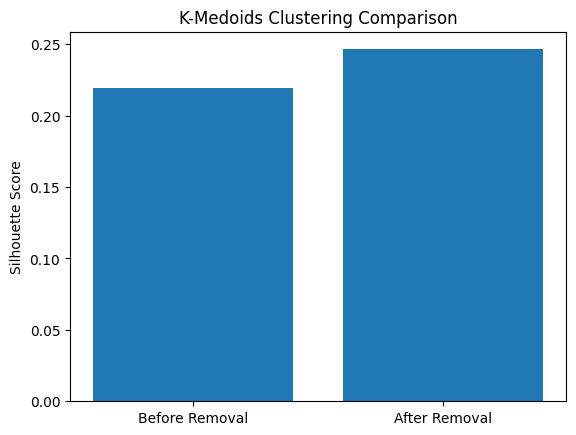

In [11]:
plt.bar(['Before Removal', 'After Removal'],
        [score_before, score_after])

plt.title('K-Medoids Clustering Comparison')
plt.ylabel('Silhouette Score')
plt.show()

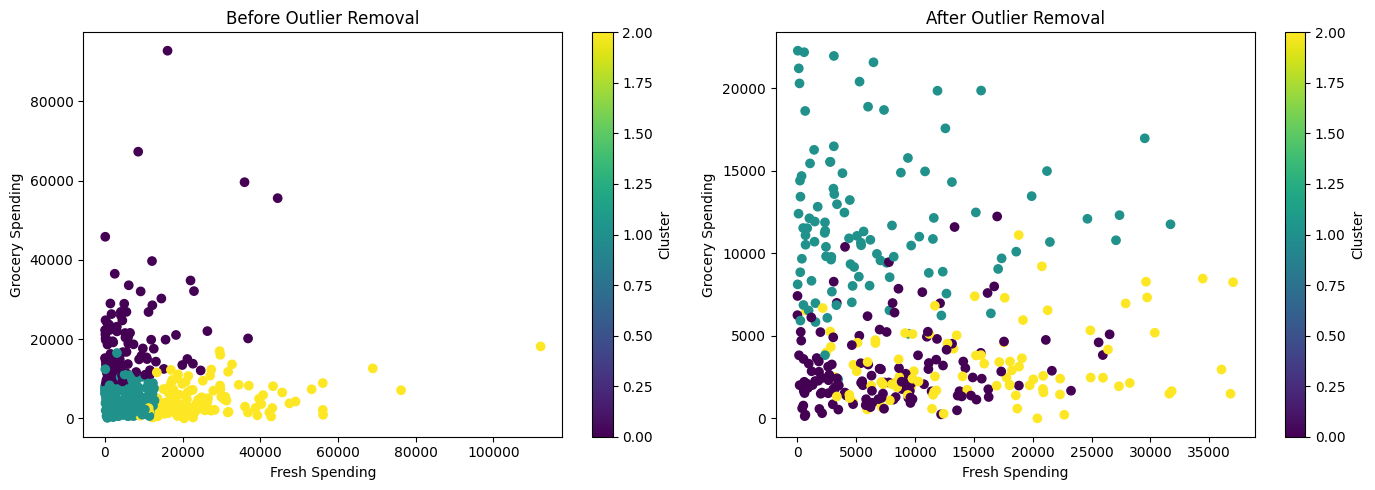

In [12]:
plt.figure(figsize=(14, 5))

# Before outlier removal
plt.subplot(1, 2, 1)
plt.scatter(x['Fresh'], x['Grocery'], c=labels, cmap='viridis')
plt.title('Before Outlier Removal')
plt.xlabel('Fresh Spending')
plt.ylabel('Grocery Spending')
plt.colorbar(label='Cluster')

# After outlier removal
plt.subplot(1, 2, 2)
plt.scatter(x_clean['Fresh'], x_clean['Grocery'],
            c=labels_clean, cmap='viridis')
plt.title('After Outlier Removal')
plt.xlabel('Fresh Spending')
plt.ylabel('Grocery Spending')
plt.colorbar(label='Cluster')

plt.tight_layout()
plt.show()